# 09 · Fase 3: tráfico y canasta

Estima la **fase 3** de `metodologia.tex`: si las promociones de una categoría atraen clientes a la tienda (tráfico) o solo redistribuyen el gasto dentro de la visita (canasta). Son regresiones **diarias** por mínimos cuadrados ordinarios, no sobre el panel SKU‑día: la variable de tráfico existe solo a nivel de tienda y día (D‑12).

**1. Modelo de tráfico.** Una regresión sobre los días de operación, con las transacciones $T_t$ (número de boletas) como variable dependiente:

$$
\log T_t = \alpha + \gamma_{\mathrm{dow}(t)} + \tau_{m(t)} + \mathbf{h}_t'\boldsymbol\theta + \sum_{k\in\mathcal{K}}\phi_k\,P_{kt} + u_t
$$

$\phi_k$ mide el poder de la categoría $k$ como **gancho de tráfico**.

**2. Descomposición exacta tráfico / canasta.** Con las ventas de la categoría $j$ agregadas por día, $Y_{jt}=\sum_{i\in j} y_{it}$, la identidad

$$
\log(1+Y_{jt}) = \log T_t + \log\frac{1+Y_{jt}}{T_t}
\qquad\Longrightarrow\qquad
\beta^{\mathrm{total}}_{jk} = \phi_k + \beta^{\mathrm{canasta}}_{jk}
$$

se cumple **coeficiente por coeficiente** si las tres ecuaciones (tráfico, total y canasta) se estiman con los mismos días, los mismos regresores y los mismos efectos fijos. Por eso las 21 regresiones de este notebook comparten una única matriz de diseño. $\beta^{\mathrm{canasta}}_{jk}$ es el efecto dentro de la visita, una vez descontado el tráfico.

Errores estándar HAC de Newey‑West (D‑15). Con 542 días la potencia es limitada: se reportan **intervalos de confianza**, no solo significancia (`metodologia.md` §3, fase 3).

| | |
|---|---|
| **Entrada** | `panel_t44_sku_dia.parquet`, `calendario_t44.csv`, `exposicion_t44_categorias_dia.csv`, `resultados/tablas/fase2_efectos_cruzados.csv` (solo para el Paso 9) |
| **Tablas** | `fase3_trafico.csv`, `fase3_descomposicion.csv`, `fase3_ajuste.csv`, `fase3_resultados.xlsx` |
| **Figuras** | `fase3_grafico_trafico.png`, `fase3_grafico_descomposicion.png`, `fase3_tabla1_trafico.png`, `fase3_tabla2_descomposicion_propia.png`, `fase3_tabla3_pares_destacados.png` |
| **Decisiones que implementa** | D‑06, D‑07, D‑09, D‑10, D‑12, D‑13, D‑15, D‑16, D‑20, D‑26, D‑28, D‑30 |

**Relación con las fases anteriores.** Este notebook **no repite** nada de las fases 1 y 2: usa las mismas variables de intensidad promocional que ya construyó `03_exposiciones` (columnas `p__<CATEGORÍA>`) y el mismo calendario de `02_calendario`, pero con otra unidad de análisis (día, no SKU‑día), otra variable dependiente (transacciones y ventas agregadas) y otro estimador (MCO, no PPML). Los efectos propios, de clase y de categoría quedan en `05_fase1_v2`; los efectos entre categorías a nivel SKU, en `07_fase2`. El Paso 9 solo compara con la fase 2 para verificar coherencia.

**Nota sobre el número de días.** `metodologia.md` §3 menciona 588 días (590 menos los dos días sin dato de `transactions`), cifra escrita antes de aplicar la exclusión de la ventana del terremoto. Como D‑09 excluye esa ventana de la muestra de estimación y `INSTRUCCIONES.md` §8 lo pide de forma explícita ("excluir la ventana del terremoto y los dos días sin dato de transacciones"), la muestra efectiva es de **542 días**. No se cambia nada de la metodología: solo se aplican las dos exclusiones ya decididas.

## Paso 1. Librerías y parámetros

In [1]:
# ------------------------------------------------------------------------------------------------------------
# Este notebook estima la fase 3 (tráfico y canasta): el modelo de transacciones diarias y la descomposición
# exacta del efecto total de cada categoría en un componente de tráfico y un componente de canasta.
# ------------------------------------------------------------------------------------------------------------
# Implementación: grupo de tesis
# Fecha de versión: 2026-11-10
# ------------------------------------------------------------------------------------------------------------

# Librerías
# ------------------------------------------------------------------------------------------------------------
import os
import re

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

# Parámetros del modelo
# ------------------------------------------------------------------------------------------------------------
# D-28 y D-30: núcleo de 10 categorías; primero las sin programa, luego las con programa (mismo orden que la fase 2)
categorias = [
    "BEVERAGES", "GROCERY I", "CLEANING", "DAIRY", "BREAD/BAKERY", "LIQUOR,WINE,BEER",
    "MEATS", "POULTRY", "DELI", "PRODUCE",
]
categorias_programa = ["MEATS", "POULTRY", "DELI", "PRODUCE"]   # D-26

# D-10 y D-13: controles de calendario (los mismos de las fases 1 y 2)
controles_calendario = [
    "dia_libre", "adicional", "dia_laboral_recuperado", "evento_comercial", "evento_otro", "dia_pago", "post_pago",
]

variable_trafico = "transactions"   # D-12: variable dependiente del modelo de tráfico, nunca un control
variable_ventas = "unit_sales"      # D-20: en los agregados por categoría se usan las ventas netas
efectos_fijos = ["dow", "mes"]      # D-16: día de la semana y año-mes
rezagos_hac = 7                     # D-15: Newey-West con 7 a 14 rezagos; se usa el extremo inferior
delta_p = 0.10                      # efectos de proporciones: +10 puntos porcentuales del surtido
alfa = 0.05                         # D-15: Benjamini-Hochberg al 5 %

# Columna de intensidad de cada categoría (mismo criterio de nombres que 03_exposiciones)
columna_categoria = {c: "p__" + re.sub(r"[^A-Z0-9]+", "_", c).strip("_") for c in categorias}
regresores_intensidad = [columna_categoria[c] for c in categorias]

# Formato de las figuras (igual que 05_fase1_v2 y 06_figuras_poster)
decimales = 1
color_neutro, color_negativo, color_positivo = "#1f5fa6", "#c0392b", "#27ae60"
color_significativo, color_cabecera = "#8fb5db", "#13213c"
color_trafico, color_canasta = "#1f5fa6", "#e0a526"

# Rutas
# ------------------------------------------------------------------------------------------------------------
ruta_procesados = os.path.join("..", "data", "procesados")
ruta_tablas = os.path.join("resultados", "tablas")
ruta_figuras = os.path.join("resultados", "figuras")
os.makedirs(ruta_tablas, exist_ok=True)
os.makedirs(ruta_figuras, exist_ok=True)
prefijo = "fase3"

## Paso 2. Importar los datos

Tres archivos, todos producidos por la versión limpia. Del panel SKU‑día solo se necesitan tres columnas, porque la fase 3 trabaja con agregados diarios. Los CSV se leen con `parse_dates=["date"]` para que las uniones no pierdan filas (`INSTRUCCIONES.md` §11.9).

In [2]:
# Leer solo las columnas del panel que se necesitan para agregar las ventas por categoría y día
panel = pd.read_parquet(
    os.path.join(ruta_procesados, "panel_t44_sku_dia.parquet"), columns=["date", "family", variable_ventas]
)
calendario = pd.read_csv(os.path.join(ruta_procesados, "calendario_t44.csv"), parse_dates=["date"])
exposicion_categorias = pd.read_csv(
    os.path.join(ruta_procesados, "exposicion_t44_categorias_dia.csv"), parse_dates=["date"]
)

# Cifras de control del README
assert len(panel) == 1_935_758, "el panel no tiene 1.935.758 filas"
assert len(calendario) == len(exposicion_categorias) == 590, "las tablas diarias no tienen 590 días"
assert set(regresores_intensidad) <= set(exposicion_categorias.columns), "falta alguna categoría del núcleo"
assert not calendario["date"].duplicated().any(), "hay fechas repetidas en el calendario"

print(f"panel:       {len(panel):,} SKU-días")
print(f"calendario:  {len(calendario)} días de operación")
print(f"exposición:  {len(exposicion_categorias)} días x {len(regresores_intensidad)} categorías del núcleo")

panel:       1,935,758 SKU-días
calendario:  590 días de operación
exposición:  590 días x 10 categorías del núcleo


## Paso 3. Ventas agregadas por categoría y día (D‑20)

$Y_{jt}$ es la suma de las ventas de todos los SKUs activos de la categoría $j$ el día $t$. Se usa `unit_sales` (ventas **netas**, con las devoluciones) y no `unit_sales_ppml`: D‑20 trunca en cero solo el panel SKU‑día que alimenta a PPML y mantiene las ventas netas en los agregados.

Como el panel ya contiene una fila por SKU activo y día (con cero en los días sin venta, D‑24), la suma por categoría y día no necesita ningún relleno: los 590 días están completos para las diez categorías.

In [3]:
# Sumar las ventas netas de cada categoría del núcleo por día (D-20)
ventas_categoria = (
    panel.loc[panel["family"].isin(categorias)]
    .groupby(["family", "date"], observed=True)[variable_ventas]
    .sum()
    .unstack("family")
    .reindex(columns=categorias)
)

# Verificar que no falte ningún día ni ninguna categoría
assert ventas_categoria.shape == (590, len(categorias)), "el agregado no tiene 590 días x 10 categorías"
assert ventas_categoria.notna().all().all(), "hay días sin ventas agregadas en alguna categoría"

print(ventas_categoria.describe().loc[["min", "mean", "max"]].round(0).to_string())

family  BEVERAGES  GROCERY I  CLEANING   DAIRY  BREAD/BAKERY  LIQUOR,WINE,BEER   MEATS  POULTRY    DELI  PRODUCE
min        5293.0     5181.0    1141.0  1572.0         830.0               0.0   411.0    578.0   270.0   5219.0
mean      10389.0    10782.0    2591.0  2855.0        1683.0             343.0   973.0   1341.0   604.0  10264.0
max       25413.0    29670.0    5869.0  5636.0        3362.0            1276.0  1960.0   2512.0  1368.0  17824.0


## Paso 4. Muestra común de días

La identidad $\beta^{\mathrm{total}}_{jk}=\phi_k+\beta^{\mathrm{canasta}}_{jk}$ solo se cumple si las 21 regresiones usan **exactamente** los mismos días. Se aplican dos exclusiones, las dos ya decididas:

| Exclusión | Decisión | Días |
|---|---|---|
| Ventana del terremoto (2016‑04‑16 a 2016‑05‑31) | D‑09 | 46 |
| Días sin dato de `transactions` (2016‑01‑03 y 04) | D‑12 | 2 |

No se excluyen los **días de programa** (D‑26). A diferencia de las fases 1 y 2, aquí la unidad es el día y no el SKU: quitar los viernes y los miércoles dejaría el modelo sin esos días de la semana para todas las categorías a la vez. En su lugar operan los dos mecanismos que ya fija la metodología: (a) para las categorías con programa, la columna `p__<CATEGORÍA>` mide solo las promociones **fuera** del programa (`p_prop_fuera_programa` de `03_exposiciones`), y (b) el efecto fijo de día de la semana $\gamma_{\mathrm{dow}(t)}$ absorbe el programa. Por eso $\phi_k$ de MEATS, POULTRY, DELI y PRODUCE se refiere a sus promociones fuera del programa, igual que en la fase 2.

In [4]:
# Unir el calendario con la intensidad de las categorías del núcleo y con las ventas agregadas
dias = calendario.merge(exposicion_categorias[["date"] + regresores_intensidad], on="date", how="left")
dias = dias.merge(ventas_categoria.reset_index(), on="date", how="left")
assert len(dias) == 590 and not dias["date"].duplicated().any(), "una unión duplicó o perdió días"
assert dias[regresores_intensidad].notna().all().all(), "hay días sin intensidad promocional"

# Excluir la ventana del terremoto (D-09) y los días sin dato de transacciones (D-12)
sin_transacciones = dias[variable_trafico].isna()
muestra = dias.loc[~dias["ventana_terremoto"] & ~sin_transacciones].reset_index(drop=True)

print(f"Días de operación:                       {len(dias)}")
print(f"  menos la ventana del terremoto (D-09): -{int(dias['ventana_terremoto'].sum())}")
print(f"  menos los días sin transacciones:      -{int(sin_transacciones.sum())} "
      f"{[f.date().isoformat() for f in dias.loc[sin_transacciones, 'date']]}")
print(f"Días de la muestra de estimación:         {len(muestra)}")

assert len(muestra) == 542, "la muestra debe tener 542 días (590 - 46 del terremoto - 2 sin transacciones)"

Días de operación:                       590
  menos la ventana del terremoto (D-09): -46
  menos los días sin transacciones:      -2 ['2016-01-03', '2016-01-04']
Días de la muestra de estimación:         542


## Paso 5. Matriz de diseño única

Una sola matriz $X$ para las 21 regresiones. Contiene la constante, las diez intensidades $P_{kt}$, los siete indicadores de calendario y las variables ficticias de los efectos fijos de día de la semana y de año‑mes (D‑16), con una categoría de referencia en cada grupo para que no haya colinealidad con la constante.

En la ecuación del total y de la canasta de la categoría $j$ **se incluye también su propia intensidad** $P_{jt}$. Eso es necesario: la identidad se cumple coeficiente por coeficiente solo si las tres ecuaciones comparten la misma matriz de diseño. El coeficiente de la propia categoría se lee como efecto del propio surtido en promoción sobre su venta agregada, no como el efecto propio por SKU de la fase 1, que se estima con otra unidad y otro estimador.

In [5]:
def construir_matriz_diseno(muestra: pd.DataFrame) -> pd.DataFrame:
    """
    Esta función arma la matriz de diseño que comparten las 21 regresiones de la fase 3: constante, intensidad
    promocional de las diez categorías del núcleo, controles de calendario y variables ficticias de los efectos
    fijos de día de la semana y de año-mes.

    :param muestra:     un DataFrame con una fila por día de la muestra de estimación.
    :return:            un DataFrame de regresores, con la misma cantidad de filas que la muestra.
    """

    # Intensidad promocional y controles de calendario, en punto flotante
    diseno = muestra[regresores_intensidad + controles_calendario].astype(float)

    # Variables ficticias de los efectos fijos, con una categoría de referencia por grupo (D-16)
    ficticias = [pd.get_dummies(muestra[efecto], prefix=efecto, drop_first=True).astype(float)
                 for efecto in efectos_fijos]
    diseno = pd.concat([diseno] + ficticias, axis=1)

    # Quitar las columnas sin variación en la muestra (un control que no ocurre en los días estimados)
    constantes = diseno.columns[diseno.nunique() <= 1].tolist()
    if constantes:
        print(f"Columnas sin variación en la muestra, excluidas: {constantes}")
        diseno = diseno.drop(columns=constantes)

    return sm.add_constant(diseno)


diseno = construir_matriz_diseno(muestra)

# Verificar que la matriz tenga rango completo: si no, los errores estándar no son interpretables
rango = np.linalg.matrix_rank(diseno.to_numpy())
assert rango == diseno.shape[1], f"la matriz de diseño no tiene rango completo ({rango} de {diseno.shape[1]})"

print(f"Matriz de diseño: {diseno.shape[0]} días x {diseno.shape[1]} regresores (rango {rango})")
print(f"  intensidad promocional: {len(regresores_intensidad)}   calendario: {len(controles_calendario)}   "
      f"efectos fijos: {diseno.shape[1] - len(regresores_intensidad) - len(controles_calendario) - 1}")

Matriz de diseño: 542 días x 42 regresores (rango 42)
  intensidad promocional: 10   calendario: 7   efectos fijos: 24


## Paso 6. Estimación por MCO con errores HAC

Una función que estima una ecuación sobre la matriz de diseño del paso anterior, con errores estándar de Newey‑West (HAC) con 7 rezagos (D‑15). El valor p y el intervalo de 95 % usan una $t$ con $n-k$ grados de libertad (542 − 42 = 500), por coherencia con las fases 1 y 2, que también usan una $t$.

Una advertencia sobre los errores HAC: la ventana del terremoto deja un hueco en la serie, y Newey‑West supone observaciones consecutivas. El hueco es un bloque único de 46 días, así que afecta solo a los 7 rezagos que lo cruzan; conviene declararlo como limitación menor.

In [6]:
def estimar(y: np.ndarray, diseno: pd.DataFrame) -> sm.regression.linear_model.RegressionResultsWrapper:
    """
    Esta función estima una ecuación por mínimos cuadrados ordinarios con errores estándar HAC de Newey-West.

    :param y:           un arreglo con la variable dependiente (ya en logaritmos).
    :param diseno:      la matriz de diseño común de la fase 3.
    :return:            el resultado de statsmodels, con la covarianza HAC ya aplicada.
    """

    return sm.OLS(y, diseno).fit(cov_type="HAC", cov_kwds={"maxlags": rezagos_hac}, use_t=True)


def coeficientes_intensidad(modelo, ecuacion: str, categoria: str) -> pd.DataFrame:
    """
    Esta función extrae de un modelo los coeficientes de las diez intensidades promocionales, con su error
    estándar, su valor p, su intervalo de 95 % y su efecto en porcentaje por +10 puntos porcentuales.

    :param modelo:      un modelo estimado con la función estimar.
    :param ecuacion:    el nombre de la ecuación ('trafico', 'total' o 'canasta'), para identificar las filas.
    :param categoria:   la categoría afectada j ('-' en la ecuación de tráfico, que es única para la tienda).
    :return:            un DataFrame con una fila por categoría en promoción k.
    """

    intervalo = modelo.conf_int(alpha=0.05).loc[regresores_intensidad]
    tabla = pd.DataFrame(
        {
            "ecuacion":                 ecuacion,
            "categoria_afectada_j":     categoria,
            "categoria_en_promocion_k": categorias,
            "beta":                     modelo.params[regresores_intensidad].to_numpy(),
            "ee":                       modelo.bse[regresores_intensidad].to_numpy(),
            "p_valor":                  modelo.pvalues[regresores_intensidad].to_numpy(),
            "ic_inf":                   intervalo.iloc[:, 0].to_numpy(),
            "ic_sup":                   intervalo.iloc[:, 1].to_numpy(),
        }
    )

    # Efecto de +10 puntos porcentuales del surtido de k en promoción: 100 (exp(0,1 beta) - 1)
    for nombre, columna in [("efecto_pct", "beta"), ("efecto_ic_inf_pct", "ic_inf"), ("efecto_ic_sup_pct", "ic_sup")]:
        tabla[nombre] = 100 * np.expm1(delta_p * tabla[columna])

    return tabla


def indicadores_ajuste(modelo, ecuacion: str, categoria: str) -> dict:
    """
    Esta función resume el tamaño y el ajuste de una ecuación.

    :param modelo:      un modelo estimado con la función estimar.
    :param ecuacion:    el nombre de la ecuación ('trafico', 'total' o 'canasta').
    :param categoria:   la categoría afectada j ('-' en la ecuación de tráfico).
    :return:            un diccionario con una fila de la tabla de ajuste.
    """

    return {
        "ecuacion":         ecuacion,
        "categoria":        categoria,
        "n_dias":           int(modelo.nobs),
        "n_regresores":     int(modelo.df_model) + 1,
        "grados_libertad":  int(modelo.df_resid),
        "r2":               modelo.rsquared,
        "r2_ajustado":      modelo.rsquared_adj,
        "rezagos_hac":      rezagos_hac,
    }

## Paso 7. Modelo de tráfico: ¿qué categorías traen clientes?

$\phi_k>0$ significa que, en los días con más surtido de la categoría $k$ en promoción, la tienda emite más boletas: la categoría funciona como **gancho de tráfico**. $\phi_k<0$ no significa que la promoción espante clientes; con 542 días y diez intensidades correlacionadas con el calendario, lo más probable es que recoja el patrón del día en que esa categoría suele promocionar.

`fuera_de_soporte` marca las categorías en que +10 pp supera su variación habitual (`rango_p10_p90`: diferencia entre los percentiles 90 y 10 de $P_k$ en los días estimados), igual que en la fase 2. En esos casos el efecto a 10 pp es una extrapolación.

In [7]:
# Estimar la ecuación de tráfico: log de las transacciones diarias (D-12)
log_trafico = np.log(muestra[variable_trafico].to_numpy())
modelo_trafico = estimar(log_trafico, diseno)

trafico = coeficientes_intensidad(modelo_trafico, "trafico", "-")

# Variación habitual de la intensidad de cada categoría en los días estimados (igual que en la fase 2)
rango_p10_p90 = pd.Series(
    {k: muestra[columna_categoria[k]].quantile(0.9) - muestra[columna_categoria[k]].quantile(0.1)
     for k in categorias},
    name="rango_p10_p90",
)
trafico["rango_p10_p90_k"] = trafico["categoria_en_promocion_k"].map(rango_p10_p90)
trafico["fuera_de_soporte"] = trafico["rango_p10_p90_k"] < delta_p

# D-15: Benjamini-Hochberg sobre los diez efectos de tráfico
trafico["p_bh"] = multipletests(trafico["p_valor"], alpha=alfa, method="fdr_bh")[1]
trafico["significativo"] = trafico["p_bh"] < alfa
trafico["clasificacion"] = np.select(
    [trafico["significativo"] & (trafico["beta"] > 0), trafico["significativo"] & (trafico["beta"] < 0)],
    ["atrae tráfico", "reduce tráfico"], "sin efecto",
)

print(f"R2 del modelo de tráfico: {modelo_trafico.rsquared:.3f}   "
      f"días: {int(modelo_trafico.nobs)}   grados de libertad: {int(modelo_trafico.df_resid)}\n")
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(trafico.set_index("categoria_en_promocion_k")[
        ["beta", "ee", "efecto_pct", "efecto_ic_inf_pct", "efecto_ic_sup_pct", "p_valor", "p_bh",
         "clasificacion", "rango_p10_p90_k", "fuera_de_soporte"]
    ])

R2 del modelo de tráfico: 0.796   días: 542   grados de libertad: 500



,beta,ee,efecto_pct,efecto_ic_inf_pct,efecto_ic_sup_pct,p_valor,p_bh,clasificacion,rango_p10_p90_k,fuera_de_soporte
categoria_en_promocion_k,,,,,,,,,,
BEVERAGES,0.248,0.130,2.508,-0.083,5.165,0.058,0.193,sin efecto,0.123,False
GROCERY I,0.048,0.192,0.485,-3.239,4.352,0.801,0.801,sin efecto,0.077,True
CLEANING,0.054,0.158,0.537,-2.535,3.706,0.735,0.801,sin efecto,0.120,False
DAIRY,0.185,0.094,1.870,-0.001,3.776,0.050,0.193,sin efecto,0.158,False
BREAD/BAKERY,-0.123,0.146,-1.222,-4.014,1.652,0.400,0.572,sin efecto,0.108,False
"LIQUOR,WINE,BEER",0.030,0.119,0.301,-2.011,2.669,0.800,0.801,sin efecto,0.167,False
MEATS,0.032,0.024,0.323,-0.159,0.807,0.189,0.472,sin efecto,0.037,True
POULTRY,0.131,0.125,1.315,-1.142,3.834,0.296,0.572,sin efecto,0.022,True
DELI,-0.239,0.069,-2.364,-3.685,-1.024,0.001,0.006,reduce tráfico,0.176,False


## Paso 8. Descomposición tráfico / canasta

Para cada una de las diez categorías objetivo $j$ se estiman dos ecuaciones más sobre la misma matriz de diseño:

| Ecuación | Variable dependiente | Coeficiente de $P_{kt}$ |
|---|---|---|
| Total | $\log(1+Y_{jt})$ | $\beta^{\mathrm{total}}_{jk}$: efecto sobre la venta agregada de $j$ |
| Canasta | $\log\dfrac{1+Y_{jt}}{T_t}=\log(1+Y_{jt})-\log T_t$ | $\beta^{\mathrm{canasta}}_{jk}$: efecto sobre la venta **por boleta** |

La verificación del final del paso comprueba la identidad $\beta^{\mathrm{total}}_{jk}-\phi_k-\beta^{\mathrm{canasta}}_{jk}=0$ en los 100 pares. No es un supuesto: se cumple porque MCO es lineal en la variable dependiente y las tres ecuaciones comparten $X$. Si el `assert` fallara, significaría que alguna ecuación se estimó con otra muestra u otros regresores.

In [8]:
# Columnas que comparten las 21 ecuaciones (la tabla de tráfico tiene además sus propias columnas de lectura)
columnas_coeficientes = [
    "ecuacion", "categoria_afectada_j", "categoria_en_promocion_k", "beta", "ee", "p_valor", "ic_inf", "ic_sup",
    "efecto_pct", "efecto_ic_inf_pct", "efecto_ic_sup_pct",
]

coeficientes = [trafico[columnas_coeficientes]]
ajuste = [indicadores_ajuste(modelo_trafico, "trafico", "-")]
for categoria in categorias:
    # Total: log(1 + Y_jt); canasta: log((1 + Y_jt) / T_t), es decir, el total menos el tráfico
    log_total = np.log1p(muestra[categoria].to_numpy())
    modelo_total = estimar(log_total, diseno)
    modelo_canasta = estimar(log_total - log_trafico, diseno)

    for ecuacion, modelo in [("total", modelo_total), ("canasta", modelo_canasta)]:
        coeficientes.append(coeficientes_intensidad(modelo, ecuacion, categoria)[columnas_coeficientes])
        ajuste.append(indicadores_ajuste(modelo, ecuacion, categoria))

coeficientes = pd.concat(coeficientes, ignore_index=True)
ajuste = pd.DataFrame(ajuste)

# Armar una fila por par (j, k) con los tres coeficientes y verificar la identidad de la descomposición
descomposicion = coeficientes.loc[coeficientes["ecuacion"] != "trafico"].pivot(
    index=["categoria_afectada_j", "categoria_en_promocion_k"],
    columns="ecuacion",
    values=["beta", "ee", "p_valor", "ic_inf", "ic_sup", "efecto_pct", "efecto_ic_inf_pct", "efecto_ic_sup_pct"],
)
descomposicion.columns = [f"{ecuacion}_{medida}" for medida, ecuacion in descomposicion.columns]
descomposicion = descomposicion.reset_index()

# Agregar el componente de tráfico (igual para toda la tienda) y comprobar la identidad
columnas_trafico = ["beta", "ee", "p_valor", "p_bh", "efecto_pct", "efecto_ic_inf_pct", "efecto_ic_sup_pct"]
descomposicion = descomposicion.merge(
    trafico[["categoria_en_promocion_k"] + columnas_trafico].add_prefix("trafico_"),
    left_on="categoria_en_promocion_k", right_on="trafico_categoria_en_promocion_k",
).drop(columns="trafico_categoria_en_promocion_k")

descomposicion["residuo_identidad"] = (
    descomposicion["total_beta"] - descomposicion["trafico_beta"] - descomposicion["canasta_beta"]
)
assert descomposicion["residuo_identidad"].abs().max() < 1e-8, "la identidad tráfico + canasta = total no se cumple"

print(f"Ecuaciones estimadas: {len(ajuste)} (1 de tráfico + {len(categorias)} totales + {len(categorias)} de canasta)")
print(f"Pares (j, k): {len(descomposicion)}")
print(f"Residuo máximo de la identidad total = tráfico + canasta: "
      f"{descomposicion['residuo_identidad'].abs().max():.2e}\n")
display(ajuste.set_index(["ecuacion", "categoria"]).round(3))

Ecuaciones estimadas: 21 (1 de tráfico + 10 totales + 10 de canasta)
Pares (j, k): 100
Residuo máximo de la identidad total = tráfico + canasta: 1.82e-14



,,n_dias,n_regresores,grados_libertad,r2,r2_ajustado,rezagos_hac
ecuacion,categoria,,,,,,
trafico,-,542,42,500,0.796,0.780,7
total,BEVERAGES,542,42,500,0.855,0.843,7
canasta,BEVERAGES,542,42,500,0.806,0.791,7
total,GROCERY I,542,42,500,0.829,0.815,7
canasta,GROCERY I,542,42,500,0.766,0.746,7
total,CLEANING,542,42,500,0.707,0.682,7
canasta,CLEANING,542,42,500,0.519,0.479,7
total,DAIRY,542,42,500,0.843,0.830,7
canasta,DAIRY,542,42,500,0.821,0.806,7


## Paso 9. Corrección por comparaciones múltiples (D‑15)

Benjamini‑Hochberg al 5 %, en familias separadas, siguiendo el criterio de las fases 1 y 2: los **efectos cruzados** ($j\neq k$) se corrigen, y el efecto de la **propia** categoría ($j=k$) se reporta con su valor p sin corregir, igual que los efectos propios de la fase 1.

| Familia | Pruebas |
|---|---|
| Tráfico, $\phi_k$ (Paso 7) | 10 |
| Efecto total cruzado, $\beta^{\mathrm{total}}_{jk}$, $j\neq k$ | 90 |
| Efecto canasta cruzado, $\beta^{\mathrm{canasta}}_{jk}$, $j\neq k$ | 90 |

`clasificacion_total` y `clasificacion_canasta` usan el p corregido en los pares cruzados y el p sin corregir en la diagonal; son la conclusión que se reporta.

In [9]:
# Separar la diagonal (propia categoría) de los pares cruzados
es_cruzado = descomposicion["categoria_afectada_j"] != descomposicion["categoria_en_promocion_k"]
assert es_cruzado.sum() == len(categorias) * (len(categorias) - 1), "faltan pares cruzados"

for ecuacion in ["total", "canasta"]:
    # D-15: Benjamini-Hochberg solo sobre los 90 efectos cruzados de cada ecuación
    descomposicion.loc[es_cruzado, f"{ecuacion}_p_bh"] = multipletests(
        descomposicion.loc[es_cruzado, f"{ecuacion}_p_valor"], alpha=alfa, method="fdr_bh"
    )[1]

    # El criterio de significancia es el p corregido donde existe y el p sin corregir en la diagonal
    criterio = descomposicion[f"{ecuacion}_p_bh"].fillna(descomposicion[f"{ecuacion}_p_valor"])
    descomposicion[f"{ecuacion}_p_criterio"] = criterio
    descomposicion[f"{ecuacion}_significativo"] = criterio < alfa
    descomposicion[f"clasificacion_{ecuacion}"] = np.select(
        [descomposicion[f"{ecuacion}_significativo"] & (descomposicion[f"{ecuacion}_beta"] > 0),
         descomposicion[f"{ecuacion}_significativo"] & (descomposicion[f"{ecuacion}_beta"] < 0)],
        ["sinergia", "canibalización"], "sin efecto",
    )

# Marcar el componente dominante y el soporte de la variación de k (igual que en la fase 2)
descomposicion["componente_dominante"] = np.where(
    descomposicion["trafico_beta"].abs() >= descomposicion["canasta_beta"].abs(), "tráfico", "canasta"
)
descomposicion["rango_p10_p90_k"] = descomposicion["categoria_en_promocion_k"].map(rango_p10_p90)
descomposicion["fuera_de_soporte"] = descomposicion["rango_p10_p90_k"] < delta_p
descomposicion["es_propia"] = ~es_cruzado

print("Clasificación de los 90 pares cruzados (efecto total vs. efecto canasta):")
print(pd.crosstab(descomposicion.loc[es_cruzado, "clasificacion_total"],
                  descomposicion.loc[es_cruzado, "clasificacion_canasta"], margins=True))
print(f"\nPares cruzados con p < 0,05 sin corregir (total): "
      f"{(descomposicion.loc[es_cruzado, 'total_p_valor'] < alfa).sum()} de {int(es_cruzado.sum())}; "
      f"menor p corregido: {descomposicion.loc[es_cruzado, 'total_p_bh'].min():.3f}")

Clasificación de los 90 pares cruzados (efecto total vs. efecto canasta):
clasificacion_canasta  sin efecto  All
clasificacion_total                   
canibalización                  4    4
sin efecto                     86   86
All                            90   90

Pares cruzados con p < 0,05 sin corregir (total): 13 de 90; menor p corregido: 0.000


## Paso 10. Coherencia con la fase 2

La fase 2 estima los efectos entre categorías con PPML sobre el panel SKU‑día; aquí el mismo tipo de efecto aparece como $\beta^{\mathrm{total}}_{jk}$, con MCO sobre la venta agregada. `metodologia.md` §3 describe esa comparación como una comprobación simple: **no se esperan los mismos números**, porque cambia el estimador, la ponderación entre SKUs y la muestra (la fase 2 excluye los días de programa de las cuatro categorías con programa y pondera por SKU). Lo que se espera es que los signos coincidan más de lo que coincidirían por azar.

Este paso solo verifica coherencia; no reemplaza ni corrige la fase 2. Si el archivo de la fase 2 no está, el paso se omite sin detener el notebook.

In [10]:
archivo_fase2 = os.path.join(ruta_tablas, "fase2_efectos_cruzados.csv")
if not os.path.exists(archivo_fase2):
    print(f"No se encontró {archivo_fase2}: ejecute 07_fase2 para hacer esta comparación")
else:
    # Unir el efecto del día de la fase 2 con el efecto total de la fase 3, por par (j, k)
    fase2 = pd.read_csv(archivo_fase2)
    comparacion = fase2[["categoria_afectada_j", "categoria_en_promocion_k", "dia_efecto_10pp_pct",
                         "dia_p_valor", "clasificacion_dia"]].merge(
        descomposicion.loc[es_cruzado, ["categoria_afectada_j", "categoria_en_promocion_k", "total_efecto_pct",
                                        "total_p_valor", "clasificacion_total", "trafico_efecto_pct",
                                        "canasta_efecto_pct"]],
        on=["categoria_afectada_j", "categoria_en_promocion_k"],
    )
    assert len(comparacion) == int(es_cruzado.sum()), "la comparación con la fase 2 perdió pares"

    # Coincidencia de signos y correlación entre los dos estimadores del mismo efecto
    mismo_signo = np.sign(comparacion["dia_efecto_10pp_pct"]) == np.sign(comparacion["total_efecto_pct"])
    correlacion = comparacion["dia_efecto_10pp_pct"].corr(comparacion["total_efecto_pct"], method="spearman")

    print(f"Pares comparados: {len(comparacion)}")
    print(f"Coincidencia de signo entre la fase 2 (PPML, panel SKU) y la fase 3 (MCO, agregado): "
          f"{mismo_signo.mean():.1%}")
    print(f"Correlación de Spearman entre los dos efectos: {correlacion:.2f}")
    print("\nPares con efecto total significativo en la fase 3, con su efecto en la fase 2:")
    display(
        comparacion.loc[comparacion["clasificacion_total"] != "sin efecto"]
        .sort_values("total_p_valor")
        .set_index(["categoria_afectada_j", "categoria_en_promocion_k"])
        .round(2)
    )

Pares comparados: 90
Coincidencia de signo entre la fase 2 (PPML, panel SKU) y la fase 3 (MCO, agregado): 72.2%
Correlación de Spearman entre los dos efectos: 0.43

Pares con efecto total significativo en la fase 3, con su efecto en la fase 2:


,,dia_efecto_10pp_pct,dia_p_valor,clasificacion_dia,total_efecto_pct,total_p_valor,clasificacion_total,trafico_efecto_pct,canasta_efecto_pct
categoria_afectada_j,categoria_en_promocion_k,,,,,,,,
PRODUCE,DELI,-3.34,0.02,sin efecto,-3.93,0.0,canibalización,-2.36,-1.61
GROCERY I,DELI,-2.91,0.02,sin efecto,-4.54,0.0,canibalización,-2.36,-2.23
POULTRY,DELI,-0.88,0.67,sin efecto,-3.85,0.0,canibalización,-2.36,-1.53
MEATS,DELI,-1.14,0.58,sin efecto,-3.73,0.0,canibalización,-2.36,-1.40


## Paso 11. Figuras

Mismo formato que `05_fase1_v2` y `06_figuras_poster`: 300 dpi, punto lleno para los efectos significativos y las categorías con programa marcadas con un asterisco.

**Figura 1.** Efecto de cada categoría sobre el tráfico de la tienda, por +10 pp de su surtido en promoción, con intervalo de 95 %.

**Figura 2.** Descomposición del efecto del **propio** surtido en promoción sobre la venta agregada de la categoría ($j=k$), separada en el componente de tráfico y el de canasta. Las barras se dibujan en **puntos logarítmicos × 100** y no en porcentaje, porque la descomposición es aditiva en logaritmos ($\beta^{\mathrm{total}}=\phi+\beta^{\mathrm{canasta}}$) y no en porcentaje; con efectos de esta magnitud las dos escalas casi coinciden, pero solo la primera suma exactamente.

In [11]:
# Etiquetas y nota de las categorías con programa (D-26), igual que en 05_fase1_v2
etiquetas = {c: f"{c} *" if c in categorias_programa else c for c in categorias}
nota_programa = ("* Categoría con programa semanal fijo: su intensidad mide solo las promociones fuera del programa; "
                 "el programa queda absorbido por el efecto fijo de día de la semana (D-26).")
nota_metodo = (f"MCO sobre {len(muestra)} días; IC 95 % con errores HAC de Newey-West ({rezagos_hac} rezagos). "
               f"Tienda 44, 2016-2017.")


def formato_pct(valor: float) -> str:
    """
    Esta función formatea un porcentaje con signo y coma decimal (p. ej., '+12,3 %').

    :param valor:   el porcentaje.
    :return:        el texto formateado.
    """

    return f"{valor:+.{decimales}f} %".replace(".", ",")


def formato_p(p: float) -> str:
    """
    Esta función formatea un valor p con coma decimal ('<0,001' si es muy chico).

    :param p:   el valor p.
    :return:    el texto formateado.
    """

    return "<0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")

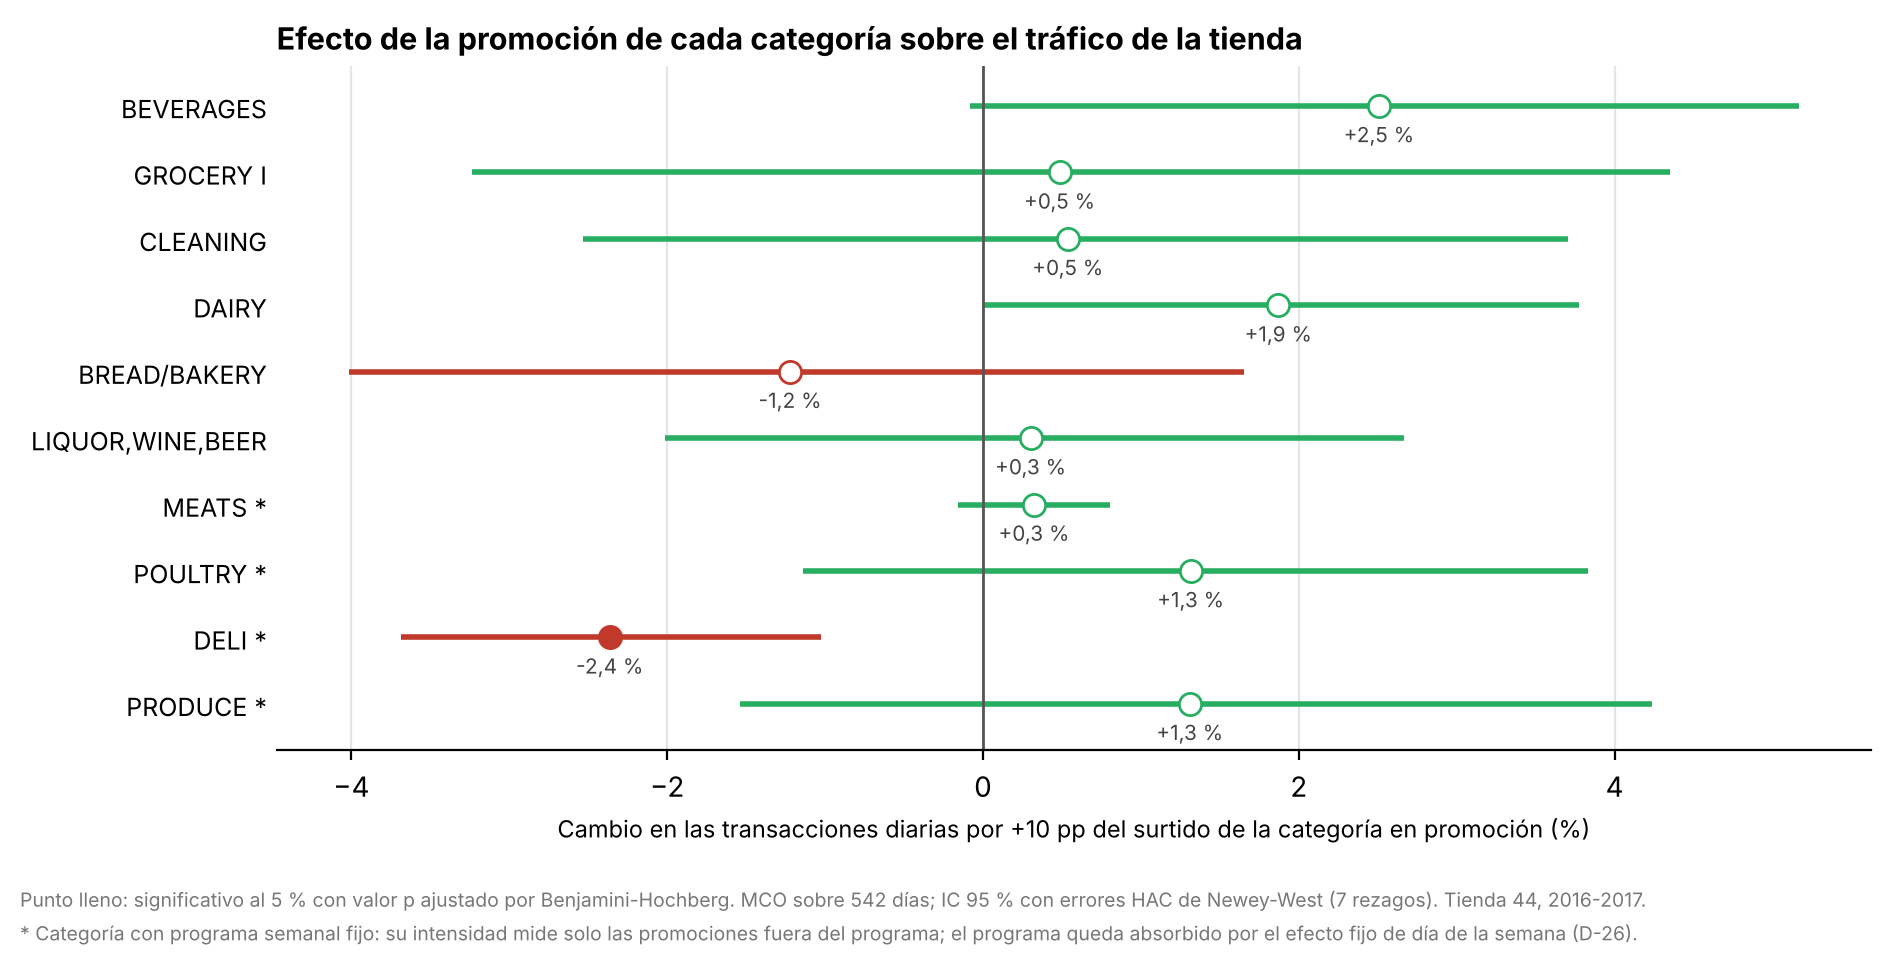

In [12]:
# Figura 1: efecto de cada categoría sobre el tráfico de la tienda
trafico_ordenado = trafico.set_index("categoria_en_promocion_k").loc[categorias]
posiciones = np.arange(len(categorias))[::-1]   # la primera categoría arriba

fig, eje = plt.subplots(figsize=(9.5, 4.8))
for posicion, categoria in zip(posiciones, categorias):
    fila = trafico_ordenado.loc[categoria]
    color = color_positivo if fila["efecto_pct"] > 0 else color_negativo
    relleno = color if fila["p_bh"] < alfa else "white"
    eje.hlines(posicion, fila["efecto_ic_inf_pct"], fila["efecto_ic_sup_pct"], color=color, linewidth=2)
    eje.plot(fila["efecto_pct"], posicion, "o", markersize=8, color=color, markerfacecolor=relleno, zorder=3)
    eje.annotate(formato_pct(fila["efecto_pct"]), (fila["efecto_pct"], posicion), textcoords="offset points",
                 xytext=(0, -13), ha="center", fontsize=7.5, color="#444444")

eje.axvline(0, color="#555555", linewidth=1)
eje.set_title("Efecto de la promoción de cada categoría sobre el tráfico de la tienda", loc="left", fontsize=11,
              fontweight="bold")
eje.set_xlabel("Cambio en las transacciones diarias por +10 pp del surtido de la categoría en promoción (%)",
               fontsize=8.5)
eje.set_yticks(posiciones, [etiquetas[c] for c in categorias], fontsize=9)
eje.set_ylim(-0.7, len(categorias) - 0.4)
eje.grid(axis="x", color="#e5e5e5")
eje.set_axisbelow(True)
eje.spines[["top", "right", "left"]].set_visible(False)
eje.tick_params(axis="y", length=0)

fig.text(0.01, 0.045, "Punto lleno: significativo al 5 % con valor p ajustado por Benjamini-Hochberg. "
         + nota_metodo, fontsize=7, color="#777777")
fig.text(0.01, 0.01, nota_programa, fontsize=7, color="#777777")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(os.path.join(ruta_figuras, f"{prefijo}_grafico_trafico.png"), dpi=300)
plt.show()

In [13]:
# Aportes del propio surtido en promoción (j = k), en puntos logarítmicos x 100 (aditivos: tráfico + canasta = total)
propia = descomposicion.loc[descomposicion["es_propia"]].set_index("categoria_afectada_j").loc[categorias]
aportes = 100 * delta_p * propia[["trafico_beta", "canasta_beta", "total_beta"]]
aportes.columns = ["trafico", "canasta", "total"]

# Fijar la escala con las categorías de magnitud habitual; las que la superan se dibujan recortadas y se anotan
magnitud = aportes.abs().max(axis=1)
dentro_de_escala = magnitud <= 3 * magnitud.median()
valores = aportes.loc[dentro_de_escala].to_numpy().ravel()
margen = 0.20 * (valores.max() - valores.min())
limites = (min(valores.min(), 0.0) - margen, valores.max() + margen)
print(f"Categorías con aportes fuera de la escala de la figura: "
      f"{aportes.index[~dentro_de_escala].tolist() or 'ninguna'}")

Categorías con aportes fuera de la escala de la figura: ['LIQUOR,WINE,BEER']


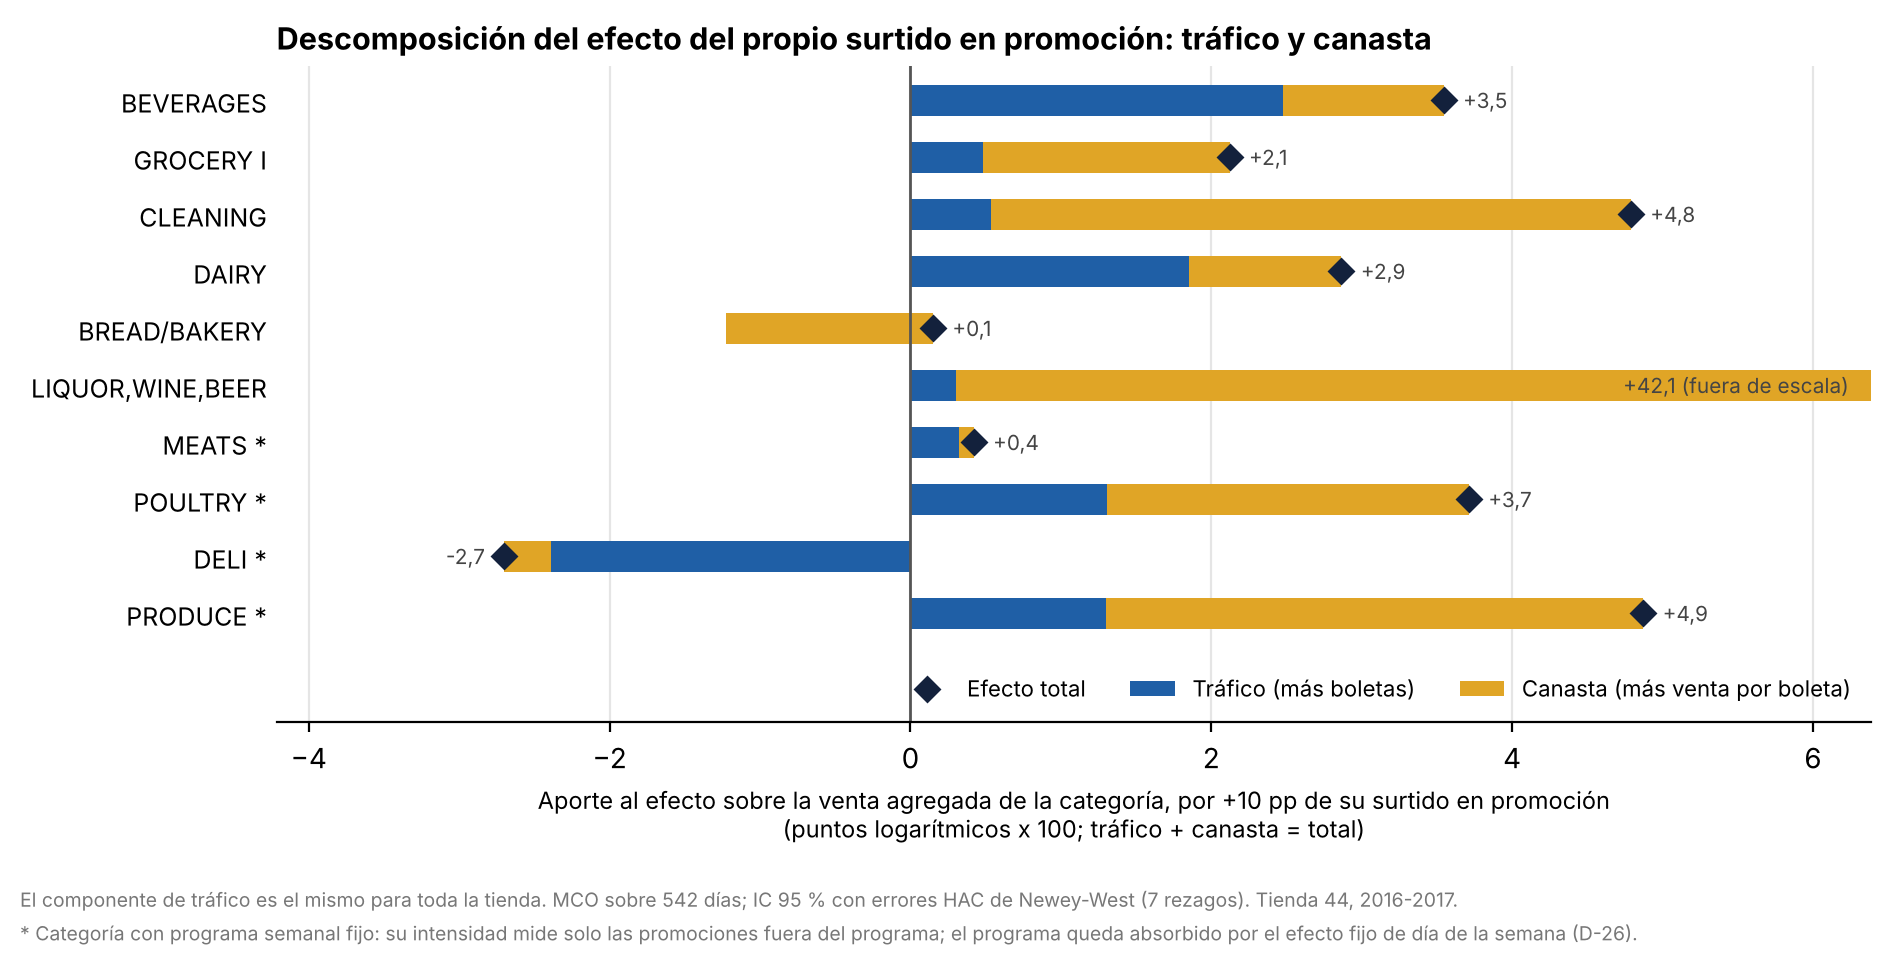

In [14]:
# Figura 2: descomposición del efecto del propio surtido en promoción (j = k)
fig, eje = plt.subplots(figsize=(9.5, 4.8))
eje.barh(posiciones, aportes["trafico"], color=color_trafico, height=0.55, label="Tráfico (más boletas)")
eje.barh(posiciones, aportes["canasta"], left=aportes["trafico"], color=color_canasta, height=0.55,
         label="Canasta (más venta por boleta)")

# Marcar el efecto total con un rombo y anotarlo hacia afuera; las barras recortadas llevan su valor en el borde
for posicion, categoria in zip(posiciones, categorias):
    total = aportes.loc[categoria, "total"]
    if dentro_de_escala[categoria]:
        eje.plot(total, posicion, "D", color=color_cabecera, markersize=6, zorder=4,
                 label="Efecto total" if categoria == categorias[0] else None)
        desplazamiento, alineacion = (7, "left") if total >= 0 else (-7, "right")
        eje.annotate(f"{total:+.1f}".replace(".", ","), (total, posicion), textcoords="offset points",
                     xytext=(desplazamiento, 0), ha=alineacion, va="center", fontsize=7.5, color="#444444")
    else:
        borde = limites[1] if total > 0 else limites[0]
        eje.annotate(f"{total:+.1f} (fuera de escala)".replace(".", ","), (borde, posicion),
                     textcoords="offset points", xytext=(-8 if total > 0 else 8, 0),
                     ha="right" if total > 0 else "left", va="center", fontsize=7.5, color="#444444")

eje.axvline(0, color="#555555", linewidth=1)
eje.set_xlim(limites)
eje.set_title("Descomposición del efecto del propio surtido en promoción: tráfico y canasta", loc="left",
              fontsize=11, fontweight="bold")
eje.set_xlabel("Aporte al efecto sobre la venta agregada de la categoría, por +10 pp de su surtido en promoción\n"
               "(puntos logarítmicos x 100; tráfico + canasta = total)", fontsize=8.5)
eje.set_yticks(posiciones, [etiquetas[c] for c in categorias], fontsize=9)
eje.set_ylim(-1.9, len(categorias) - 0.4)   # fila vacía abajo para la leyenda
eje.grid(axis="x", color="#e5e5e5")
eje.set_axisbelow(True)
eje.spines[["top", "right", "left"]].set_visible(False)
eje.tick_params(axis="y", length=0)
eje.legend(loc="lower right", ncol=3, fontsize=8, frameon=False)

fig.text(0.01, 0.045, "El componente de tráfico es el mismo para toda la tienda. " + nota_metodo,
         fontsize=7, color="#777777")
fig.text(0.01, 0.01, nota_programa, fontsize=7, color="#777777")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(os.path.join(ruta_figuras, f"{prefijo}_grafico_descomposicion.png"), dpi=300)
plt.show()

## Paso 12. Tablas para el documento

Tres tablas en PNG, con el formato de `06_figuras_poster`. Las mismas cifras están en los CSV del Paso 13, que son la fuente para cualquier número del texto (`pipeline.md` §3.6).

In [15]:
def dibujar_tabla(textos: list, colores: list, cabeceras: list, anchos: list, titulo: str, nota: str,
                  nombre_archivo: str) -> None:
    """
    Esta función dibuja una tabla con el formato de 06_figuras_poster y la guarda como PNG.

    :param textos:          una lista de filas, cada una una lista con los textos de las celdas.
    :param colores:         una lista de filas con el color de fondo de cada celda.
    :param cabeceras:       los títulos de las columnas.
    :param anchos:          el ancho relativo de cada columna.
    :param titulo:          el título de la tabla.
    :param nota:            la nota al pie.
    :param nombre_archivo:  el nombre del PNG, sin extensión.
    """

    fig, eje = plt.subplots(figsize=(11.5, 0.4 * (len(textos) + 1)))
    eje.axis("off")
    tabla = eje.table(cellText=textos, cellColours=colores, colLabels=cabeceras, colWidths=anchos, loc="center",
                      cellLoc="center")
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9.5)
    tabla.scale(1, 1.6)
    for j in range(len(cabeceras)):
        tabla[0, j].set_facecolor(color_cabecera)
        tabla[0, j].set_text_props(color="white", fontweight="bold")
    eje.set_title(titulo, loc="left", fontsize=11.5, fontweight="bold")
    eje.text(0.0, -0.08, nota, transform=eje.transAxes, fontsize=8, color="#555555", va="top")
    fig.savefig(os.path.join(ruta_figuras, nombre_archivo + ".png"), dpi=300, bbox_inches="tight")
    plt.show()

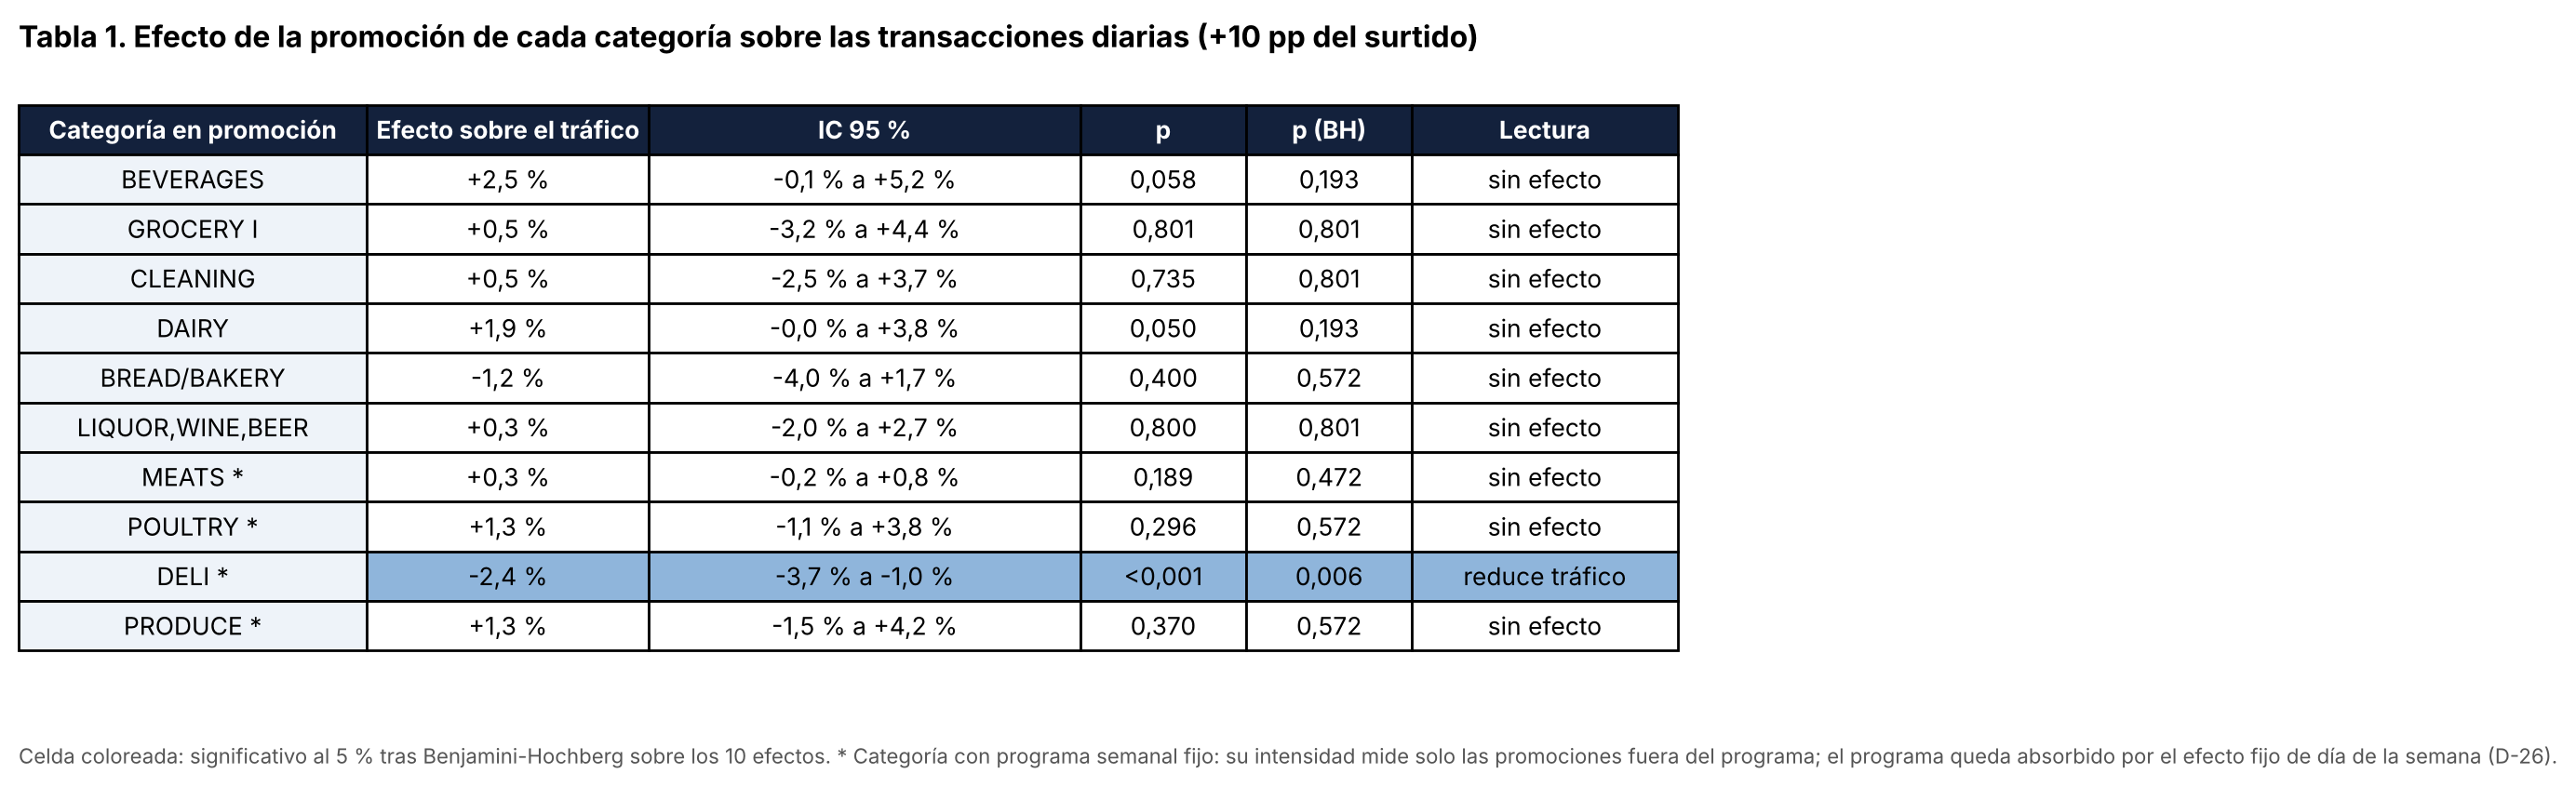

In [16]:
# Tabla 1: efecto de cada categoría sobre el tráfico de la tienda
textos, colores = [], []
for categoria in categorias:
    fila = trafico_ordenado.loc[categoria]
    significativo = fila["p_bh"] < alfa
    intervalo = f"{formato_pct(fila['efecto_ic_inf_pct'])} a {formato_pct(fila['efecto_ic_sup_pct'])}"
    textos.append([etiquetas[categoria], formato_pct(fila["efecto_pct"]), intervalo, formato_p(fila["p_valor"]),
                   formato_p(fila["p_bh"]), fila["clasificacion"]])
    colores.append(["#eef3f9"] + [color_significativo if significativo else "white"] * 5)

dibujar_tabla(
    textos, colores,
    ["Categoría en promoción", "Efecto sobre el tráfico", "IC 95 %", "p", "p (BH)", "Lectura"],
    [0.21, 0.17, 0.26, 0.10, 0.10, 0.16],
    "Tabla 1. Efecto de la promoción de cada categoría sobre las transacciones diarias (+10 pp del surtido)",
    "Celda coloreada: significativo al 5 % tras Benjamini-Hochberg sobre los 10 efectos. " + nota_programa,
    f"{prefijo}_tabla1_trafico",
)

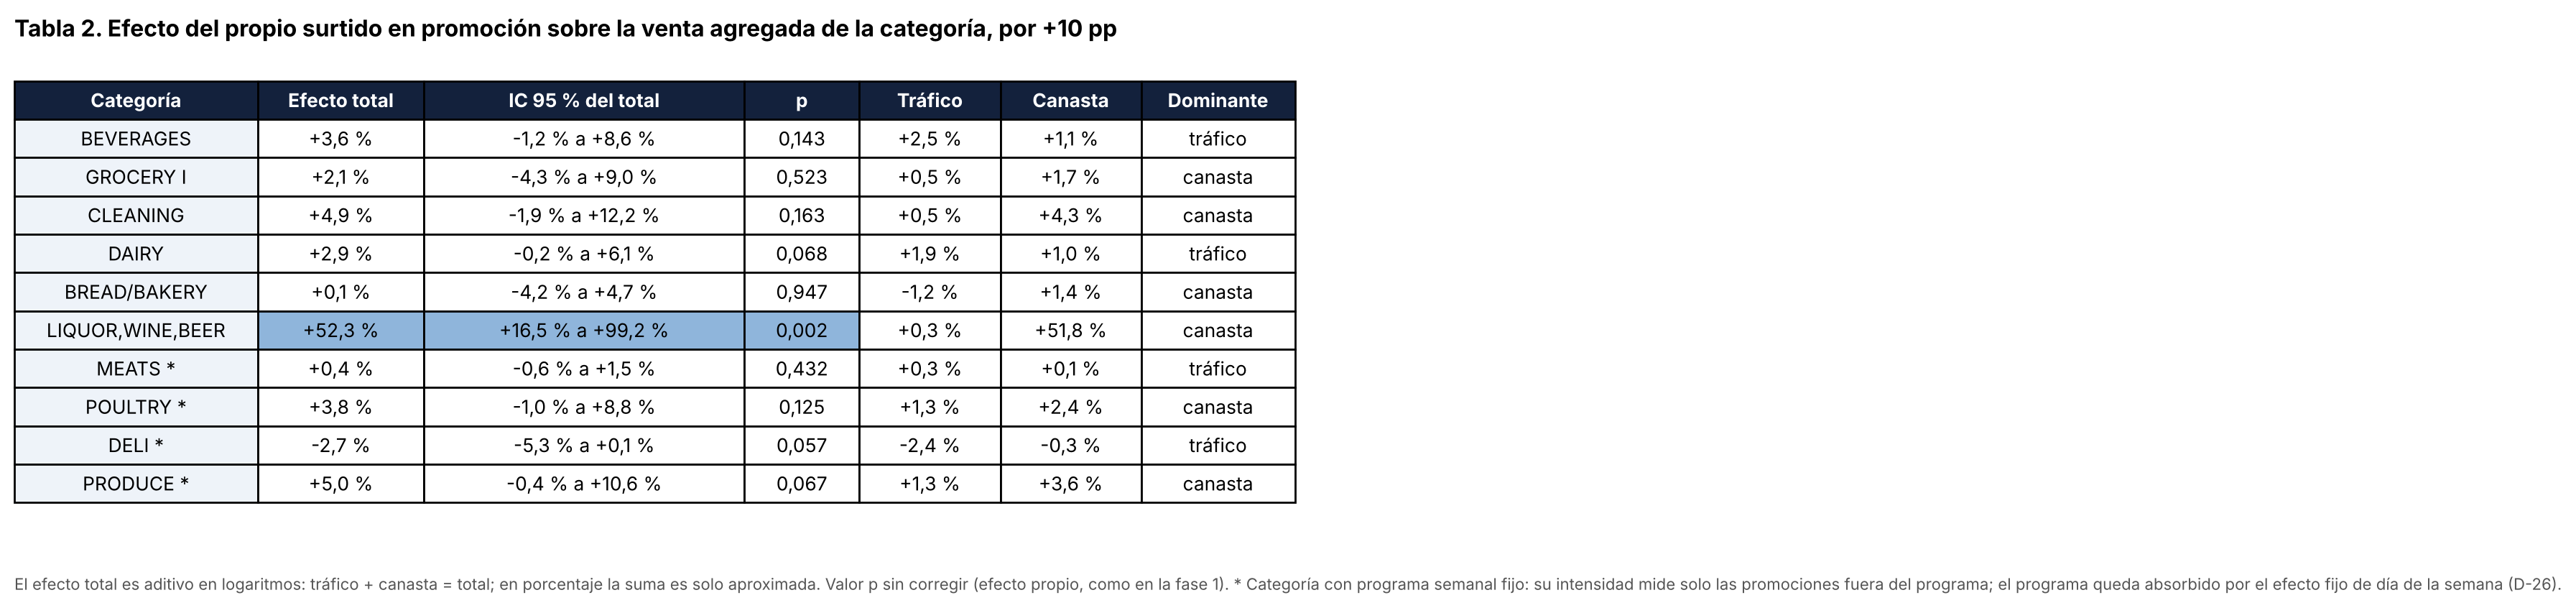

In [17]:
# Tabla 2: descomposición del efecto del propio surtido en promoción (j = k)
textos, colores = [], []
for categoria in categorias:
    fila = propia.loc[categoria]
    significativo = fila["total_p_criterio"] < alfa
    textos.append([etiquetas[categoria], formato_pct(fila["total_efecto_pct"]),
                   f"{formato_pct(fila['total_efecto_ic_inf_pct'])} a {formato_pct(fila['total_efecto_ic_sup_pct'])}",
                   formato_p(fila["total_p_valor"]), formato_pct(fila["trafico_efecto_pct"]),
                   formato_pct(fila["canasta_efecto_pct"]), fila["componente_dominante"]])
    colores.append(["#eef3f9"] + [color_significativo if significativo else "white"] * 3 + ["white"] * 3)

dibujar_tabla(
    textos, colores,
    ["Categoría", "Efecto total", "IC 95 % del total", "p", "Tráfico", "Canasta", "Dominante"],
    [0.19, 0.13, 0.25, 0.09, 0.11, 0.11, 0.12],
    "Tabla 2. Efecto del propio surtido en promoción sobre la venta agregada de la categoría, por +10 pp",
    "El efecto total es aditivo en logaritmos: tráfico + canasta = total; en porcentaje la suma es solo "
    "aproximada. Valor p sin corregir (efecto propio, como en la fase 1). " + nota_programa,
    f"{prefijo}_tabla2_descomposicion_propia",
)

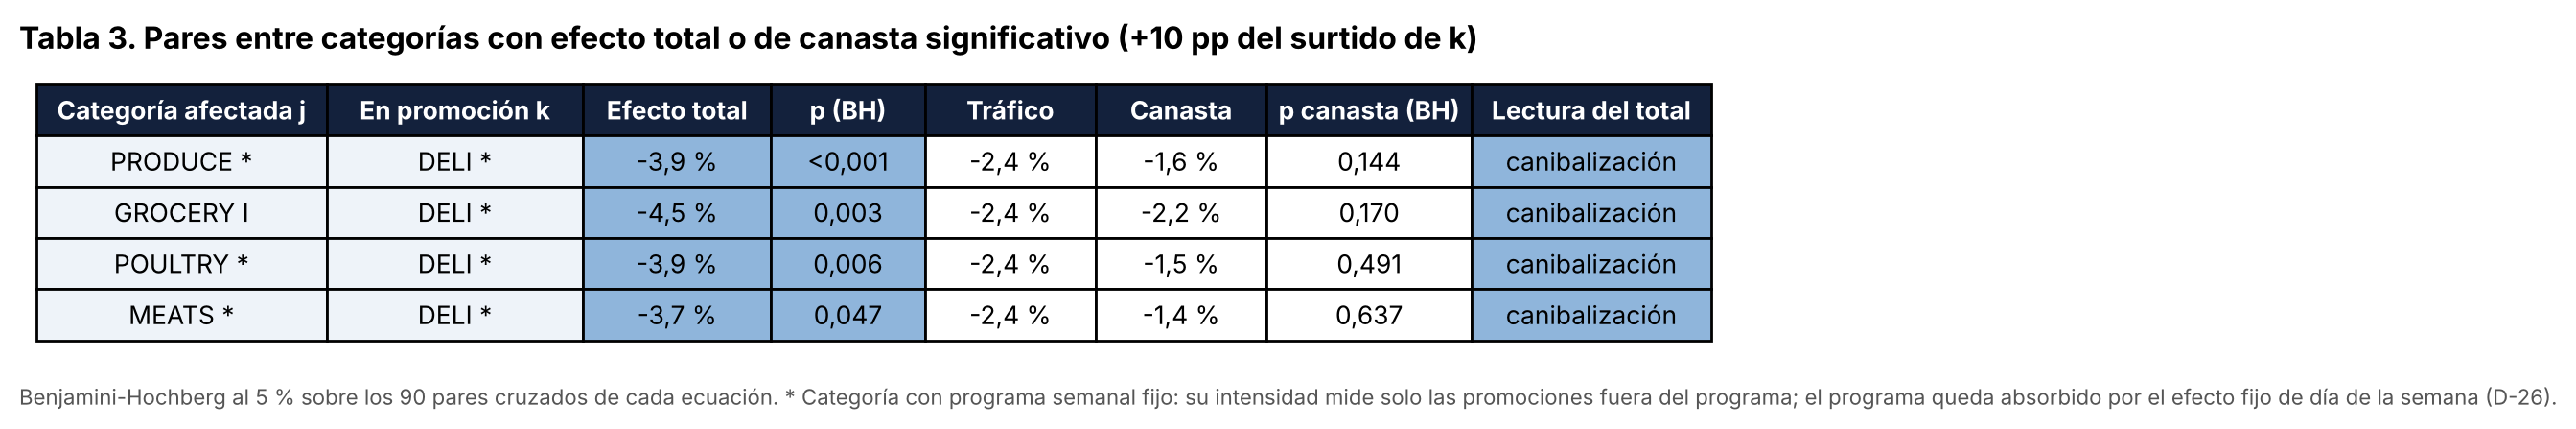

In [18]:
# Tabla 3: pares cruzados con evidencia (efecto total o de canasta significativo tras la corrección)
destacados = descomposicion.loc[
    es_cruzado & (descomposicion["total_significativo"] | descomposicion["canasta_significativo"])
].sort_values("total_p_valor")

if destacados.empty:
    print("Ningún par cruzado resultó significativo tras la corrección de Benjamini-Hochberg: no se dibuja la "
          "tabla 3. Con 542 días y 90 pares, es un resultado posible y debe reportarse como tal.")
else:
    textos, colores = [], []
    for _, fila in destacados.iterrows():
        significativo = fila["total_significativo"]
        textos.append([etiquetas[fila["categoria_afectada_j"]], etiquetas[fila["categoria_en_promocion_k"]],
                       formato_pct(fila["total_efecto_pct"]), formato_p(fila["total_p_bh"]),
                       formato_pct(fila["trafico_efecto_pct"]), formato_pct(fila["canasta_efecto_pct"]),
                       formato_p(fila["canasta_p_bh"]), fila["clasificacion_total"]])
        colores.append(["#eef3f9"] * 2 + [color_significativo if significativo else "white"] * 2
                       + ["white"] * 2 + [color_significativo if fila["canasta_significativo"] else "white"]
                       + [color_significativo if significativo else "white"])

    dibujar_tabla(
        textos, colores,
        ["Categoría afectada j", "En promoción k", "Efecto total", "p (BH)", "Tráfico", "Canasta", "p canasta (BH)",
         "Lectura del total"],
        [0.17, 0.15, 0.11, 0.09, 0.10, 0.10, 0.12, 0.14],
        "Tabla 3. Pares entre categorías con efecto total o de canasta significativo (+10 pp del surtido de k)",
        "Benjamini-Hochberg al 5 % sobre los 90 pares cruzados de cada ecuación. " + nota_programa,
        f"{prefijo}_tabla3_pares_destacados",
    )

## Paso 13. Resumen de resultados

Las cinco líneas que resumen la fase 3, generadas desde las tablas para que ninguna cifra del texto se escriba a mano (`pipeline.md` §3.6).

In [19]:
ganchos = trafico.loc[trafico["clasificacion"] == "atrae tráfico", "categoria_en_promocion_k"].tolist()
reducen = trafico.loc[trafico["clasificacion"] == "reduce tráfico", "categoria_en_promocion_k"].tolist()
cruzados_significativos = descomposicion.loc[es_cruzado & descomposicion["total_significativo"]]
canasta_significativos = descomposicion.loc[es_cruzado & descomposicion["canasta_significativo"]]
mayor_trafico = trafico.loc[trafico["beta"].idxmax()]

print("RESUMEN DE LA FASE 3")
print("-" * 112)
print(f"1. Muestra: {len(muestra)} días de operación de la tienda 44 (590 menos 46 de la ventana del terremoto y "
      f"2 sin transacciones);\n   21 ecuaciones por MCO con la misma matriz de diseño y errores HAC de "
      f"{rezagos_hac} rezagos. R2 del modelo de tráfico: {modelo_trafico.rsquared:.2f}.")
print(f"2. Ganchos de tráfico (phi_k > 0 y significativo tras Benjamini-Hochberg): "
      f"{', '.join(ganchos) if ganchos else 'ninguna de las 10 categorías del núcleo'}.")
print(f"3. Categorías con efecto negativo significativo sobre el tráfico: "
      f"{', '.join(reducen) if reducen else 'ninguna'}. El mayor efecto puntual sobre el tráfico lo tiene "
      f"{mayor_trafico['categoria_en_promocion_k']} "
      f"({mayor_trafico['efecto_pct']:+.1f} % por +10 pp, p ajustado {mayor_trafico['p_bh']:.3f}).")
print(f"4. De los {int(es_cruzado.sum())} pares cruzados, {len(cruzados_significativos)} tienen efecto total "
      f"significativo y {len(canasta_significativos)} tienen efecto de canasta significativo tras la corrección.")
print(f"5. La descomposición es exacta: el residuo máximo de total = tráfico + canasta es "
      f"{descomposicion['residuo_identidad'].abs().max():.1e}. Con {len(muestra)} días los intervalos son anchos: "
      f"un efecto\n   no significativo indica falta de información, no ausencia de efecto.")
print("-" * 112)

RESUMEN DE LA FASE 3
----------------------------------------------------------------------------------------------------------------
1. Muestra: 542 días de operación de la tienda 44 (590 menos 46 de la ventana del terremoto y 2 sin transacciones);
   21 ecuaciones por MCO con la misma matriz de diseño y errores HAC de 7 rezagos. R2 del modelo de tráfico: 0.80.
2. Ganchos de tráfico (phi_k > 0 y significativo tras Benjamini-Hochberg): ninguna de las 10 categorías del núcleo.
3. Categorías con efecto negativo significativo sobre el tráfico: DELI. El mayor efecto puntual sobre el tráfico lo tiene BEVERAGES (+2.5 % por +10 pp, p ajustado 0.193).
4. De los 90 pares cruzados, 4 tienen efecto total significativo y 0 tienen efecto de canasta significativo tras la corrección.
5. La descomposición es exacta: el residuo máximo de total = tráfico + canasta es 1.8e-14. Con 542 días los intervalos son anchos: un efecto
   no significativo indica falta de información, no ausencia de efecto.
-------

## Paso 14. Exportación

In [20]:
# Tablas en CSV (una por resultado) y un Excel con una hoja por tabla
tablas = {
    "trafico": trafico.drop(columns="ecuacion").set_index("categoria_en_promocion_k"),
    "descomposicion": descomposicion.set_index(["categoria_afectada_j", "categoria_en_promocion_k"]),
    "coeficientes": coeficientes.set_index(["ecuacion", "categoria_afectada_j", "categoria_en_promocion_k"]),
    "ajuste": ajuste.set_index(["ecuacion", "categoria"]),
}
with pd.ExcelWriter(os.path.join(ruta_tablas, f"{prefijo}_resultados.xlsx")) as excel:
    for nombre, tabla in tablas.items():
        tabla.to_csv(os.path.join(ruta_tablas, f"{prefijo}_{nombre}.csv"))
        tabla.to_excel(excel, sheet_name=nombre)

print(f"Guardado: {len(tablas)} tablas en {ruta_tablas} (CSV y {prefijo}_resultados.xlsx)")
print(f"Guardado: 5 figuras en {ruta_figuras} (prefijo {prefijo}_)")
print(f"\n>>>> Proceso finalizado <<<<")

Guardado: 4 tablas en resultados/tablas (CSV y fase3_resultados.xlsx)
Guardado: 5 figuras en resultados/figuras (prefijo fase3_)

>>>> Proceso finalizado <<<<


## Paso 15. Cómo leer estos resultados

**Qué responde esta fase.** La pregunta complementaria de la tesis (`INSTRUCCIONES.md` §2): *¿las promociones atraen clientes a la tienda o solo redistribuyen el gasto dentro de la canasta?* El modelo de tráfico contesta la primera parte con $\phi_k$; la descomposición contesta la segunda, separando cada efecto sobre la venta agregada en la parte que viene de más boletas y la que viene de más venta por boleta.

**Cómo se lee cada número.**

1. $\phi_k$ en la tabla 1: cuánto cambian las transacciones diarias de la tienda cuando 10 puntos porcentuales adicionales del surtido de la categoría $k$ están en promoción, manteniendo el día de la semana, el mes, los feriados y los días de pago. Es un efecto de **toda la tienda**, no de la categoría.
2. $\beta^{\mathrm{total}}_{jk}$: cuánto cambia la venta agregada de la categoría $j$ ante lo mismo. $\beta^{\mathrm{canasta}}_{jk}=\beta^{\mathrm{total}}_{jk}-\phi_k$ es la parte que no se explica por el número de boletas.
3. Un par con $\beta^{\mathrm{total}}_{jk}>0$ y $\beta^{\mathrm{canasta}}_{jk}\approx 0$ es sinergia **por tráfico**: la promoción de $k$ trae clientes y $j$ vende más solo porque hay más visitas. Un par con $\beta^{\mathrm{canasta}}_{jk}<0$ y $\phi_k>0$ indica que, dentro de la visita, $j$ pierde espacio en la canasta frente a $k$, aunque su venta total no caiga.

**Advertencias que deben quedar en el texto.**

1. **Potencia limitada.** Los efectos cruzados se identifican con 542 días y diez intensidades correlacionadas con el calendario. Los intervalos son anchos: un efecto no significativo es falta de información, no evidencia de un efecto nulo (`metodologia.md` §5).
2. **Programas semanales fijos (D‑26).** Para MEATS, POULTRY, DELI y PRODUCE, $\phi_k$ y sus columnas se refieren solo a las promociones **fuera** del programa. El efecto del programa no es estimable y no debe presentarse como nulo. Además, estas categorías tienen poca variación fuera del programa (`rango_p10_p90_k` bajo), así que su efecto a 10 pp es una extrapolación, marcada con `fuera_de_soporte`.
3. **Categorías de volumen bajo.** En la ecuación del total se usa $\log(1+Y_{jt})$, que es sensible cuando $Y_{jt}$ es pequeño o llega a cero. Revisen la columna `min` del Paso 3 antes de interpretar una magnitud grande en una categoría de volumen bajo (LIQUOR,WINE,BEER es el caso extremo: tiene días con venta cero).
4. **Ponderación distinta de la fase 2.** El agregado por categoría pondera cada SKU por su volumen; la fase 2 estima sobre el panel SKU‑día. Las diferencias entre $\beta^{\mathrm{total}}_{jk}$ y el efecto de la fase 2 se explican por eso y por la muestra, no son un error (Paso 10).
5. **No es causalidad fuerte.** La cadena decide cuándo promocionar; el calendario reduce el sesgo, pero no lo elimina. Hablen de "efecto asociado" (`INSTRUCCIONES.md` §11.10).
6. **Errores HAC con un hueco en la serie.** La exclusión de la ventana del terremoto corta la serie en dos tramos; Newey‑West supone días consecutivos. Es un bloque único de 46 días y afecta solo a los rezagos que lo cruzan, pero conviene declararlo.

*Escriban aquí su interpretación de los resultados obtenidos.*